In [1]:
from __future__ import annotations

import os
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

np.set_printoptions(precision=10, suppress=False, threshold=2000)


def find_project_root(start: Path | None = None) -> Path:
    start = Path.cwd() if start is None else Path(start).resolve()
    for path in [start, *start.parents]:
        if (path / "codes").is_dir() and (path / "gfn2-xtb.toml").exists():
            return path
    raise RuntimeError("Could not find project root. Run this notebook inside optxTB-MD or set PROJECT_ROOT_PATH manually.")


PROJECT_ROOT_PATH = find_project_root()
PROJECT_ROOT = str(PROJECT_ROOT_PATH)
if PROJECT_ROOT not in sys.path:
    sys.path.insert(0, PROJECT_ROOT)

print("PROJECT_ROOT_PATH:", PROJECT_ROOT_PATH)

from codes.calculate_ae_charged import vector_to_param_changes
from codes.gradients import ensure_param_file

PROJECT_ROOT_PATH: /dss/dsshome1/09/ge45fol2/cluster_vs_pbc/optxTB-MD


In [2]:
OPTIMIZATION_RUN_ID = "nsga3_pbc_efxi_loss_210083_20260529_092923"

RUN_OUTPUT_DIR = PROJECT_ROOT_PATH / "optimization/T_pbc/hpc_runs" / OPTIMIZATION_RUN_ID
results_path = RUN_OUTPUT_DIR / f"nsga3_results_pbc_EFXi_{OPTIMIZATION_RUN_ID}.npz"
if not results_path.exists():
    results_path = sorted(RUN_OUTPUT_DIR.glob("nsga3_results_pbc_EFXi_*.npz"))[0]

print(results_path)

/dss/dsshome1/09/ge45fol2/cluster_vs_pbc/optxTB-MD/optimization/T_pbc/hpc_runs/nsga3_pbc_efxi_loss_210083_20260529_092923/nsga3_results_pbc_EFXi_param_reg_nsga3_pbc_efxi_loss_210083_20260529_092923.npz


In [3]:
base_param_file = PROJECT_ROOT_PATH / "gfn2-xtb.toml"

In [4]:
param_changes = {
    "kpair": {
        "O-O": 1.0,
        "O-H": 1.0,
    },
    "H": {
        "zeff": 1.1053880000000000,
        "arep": 2.2137169999999999,
    },
    "O": {
        "zeff": 5.7844150000000001,
        "arep": 2.1657120000000001,
    },
}


def generate_parameter_info(param_changes, variation=0.30, near_one_width=0.20, positivity_eps=1e-12):
    names = []
    bounds = []
    vector = []
    structure = {}
    for elem, params in param_changes.items():
        structure[elem] = {}
        for key, value in params.items():
            if isinstance(value, list):
                structure[elem][key] = []
                for i, val in enumerate(value):
                    if key == "lgam" and i == 0:
                        structure[elem][key].append("Fixing to 1.0")
                        continue
                    par_name = f"{elem}_{key}_{i}"
                    names.append(par_name)
                    vector.append(val)
                    lo, hi = val * (1 - variation), val * (1 + variation)
                    if key == "lgam":
                        lo, hi = max(positivity_eps, 1.0 - near_one_width), 1.0 + near_one_width
                    bounds.append([min(lo, hi), max(lo, hi)])
                    structure[elem][key].append(par_name)
            else:
                par_name = f"{elem}_{key}"
                names.append(par_name)
                vector.append(value)
                if key in {"H-H", "O-O", "O-H"}:
                    lo, hi = max(positivity_eps, 1.0 - near_one_width), 1.0 + near_one_width
                elif key == "gam":
                    lo, hi = max(positivity_eps, value * (1 - variation)), value * (1 + variation)
                else:
                    lo, hi = value * (1 - variation), value * (1 + variation)
                bounds.append([min(lo, hi), max(lo, hi)])
                structure[elem][key] = par_name
    return names, bounds, vector, structure


names, bounds, default_gfn2_vector, structure = generate_parameter_info(param_changes)
default_gfn2_vector = np.asarray(default_gfn2_vector, dtype=float)
print(names)
print(default_gfn2_vector)

['kpair_O-O', 'kpair_O-H', 'H_zeff', 'H_arep', 'O_zeff', 'O_arep']
[1.       1.       1.105388 2.213717 5.784415 2.165712]


In [5]:
with np.load(results_path) as data:
    X_pareto = data["X_pareto"]
    F_pareto = data["F_pareto"]

print("X_pareto shape:", X_pareto.shape)
print("F_pareto shape:", F_pareto.shape)

X_pareto shape: (50, 6)
F_pareto shape: (50, 4)


Number of Pareto points better than GFN2-xTB: 32


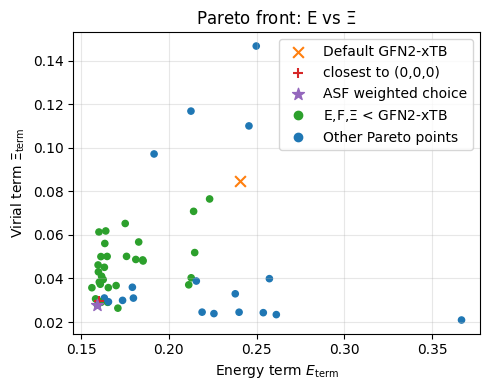

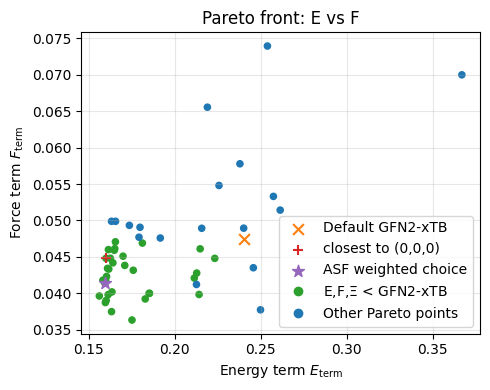

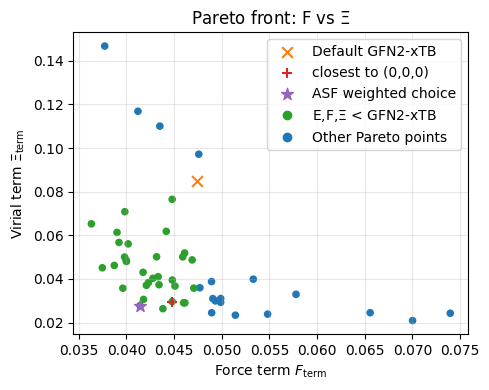

knee_selected_idx: 37
knee_objectives: [0.1599769631 0.044804822  0.0296204841 0.0417982689]
knee_params: [1.0875817618 1.005597252  1.1053099674 2.2622815474 6.1822760579
 2.1539253592]

asf_selected_idx: 3
asf_objectives: [0.1592544064 0.0414269088 0.0278153921 0.2020927495]
asf_objectives / default: [0.6625282963 0.8735080367 0.3278096234]
asf_weights [E, F, Xi]: [0.  0.5 0.5]
asf_value: 0.0537763252177601
asf_params: [1.0904385372 1.0292286967 1.1491011787 2.6624437887 5.5644239819
 1.7077977188]


In [6]:
from matplotlib.lines import Line2D

E_term = F_pareto[:, 0]
F_term = F_pareto[:, 1]
Xi_term = F_pareto[:, 2]
Reg_term = F_pareto[:, 3]

E0 = 0.2403737429
F0 = 0.0474259046
Xi0 = 0.0848522743

better_mask = (
    (E_term <= E0) &
    (F_term <= F0) &
    (Xi_term <= Xi0) &
    ((E_term < E0) | (F_term < F0) | (Xi_term < Xi0))
)

F_better = F_pareto[better_mask]
X_better = X_pareto[better_mask]

if len(F_better) == 0:
    raise ValueError("No Pareto points better than GFN2-xTB in all three objectives.")

dist2 = np.sum(F_better**2, axis=1)  # расстояние^2 до (0,0,0)
print(f'Number of Pareto points better than GFN2-xTB: {len(F_better)}')

knee_idx = np.argmin(dist2)
knee_params = X_better[knee_idx]
knee_objectives = F_better[knee_idx]
knee_selected_idx = np.where(better_mask)[0][knee_idx]


# ----------------------- ASF selection ----------------------- #
# Energy must improve / not worsen relative to default.
# Then ASF chooses a weighted compromise.
# Larger weights below mean "more important" in this implementation.
# Here: forces are most important, virials second, energies third.

mask = (
    (E_term <= E0) &
    (F_term <= F0) &
    (Xi_term <= Xi0) &
    ((E_term < E0) | (F_term < F0) | (Xi_term < Xi0))
)

# 2. Регуляризация как constraint.
# Если ты считаешь, что все Reg значения терпимые, оставь np.inf.
R_max = np.inf


mask = mask & (Reg_term <= R_max)

F_cand = F_pareto[mask]
X_cand = X_pareto[mask]
idx_cand = np.flatnonzero(mask)

if len(F_cand) == 0:
    raise ValueError("No candidates after E/Reg filtering.")

# 3. ASF только для E и F
weights = np.array([0.0, 0.5, 0.5])  # E, F, Xi
weights = weights / weights.sum()

F_norm = F_cand[:, :3] / np.array([E0, F0, Xi0])

ideal = np.min(F_norm, axis=0)

rho = 1e-6
delta = F_norm - ideal

asf_values = (
    np.max(weights * delta, axis=1)
    + rho * np.sum(weights * delta, axis=1)
)

j = np.argmin(asf_values)

asf_selected_idx = idx_cand[j]
asf_params = X_cand[j]
asf_objectives = F_cand[j]


colors = np.where(
    np.where(F_pareto[:, 0] < E0, True, False) *
    np.where(F_pareto[:, 1] < F0, True, False) *
    np.where(F_pareto[:, 2] < Xi0, True, False) == True,
    'tab:green',
    'tab:blue'
)

green_proxy = Line2D([0], [0], marker='o', linestyle='', color='tab:green', label='E,F,Xi < GFN2')
blue_proxy = Line2D([0], [0], marker='o', linestyle='', color='tab:blue', label='Other Pareto points')


plt.figure(figsize=(5, 4))
plt.scatter(E_term, Xi_term, s=20, c=colors, label="_nolegend_")
plt.scatter([E0], [Xi0], s=60, marker="x", c='tab:orange', label="Default GFN2-xTB")
plt.scatter([knee_objectives[0]], [knee_objectives[2]], s=60, marker="+", c='tab:red', label="closest to (0,0,0)")
plt.scatter([asf_objectives[0]], [asf_objectives[2]], s=80, marker="*", c='tab:purple', label="ASF weighted choice")
plt.xlabel("Energy term $E_{\\text{term}}$")
plt.ylabel("Virial term $\\Xi_{\\text{term}}$")
plt.title("Pareto front: E vs $\\Xi$")
plt.grid(True, alpha=0.3)
ax = plt.gca()
handles, labels = ax.get_legend_handles_labels()
handles.extend([green_proxy, blue_proxy])
labels.extend([r'E,F,$\Xi$ < GFN2-xTB', 'Other Pareto points'])
plt.legend(handles, labels)
plt.tight_layout()
plt.show()


plt.figure(figsize=(5, 4))
plt.scatter(E_term, F_term, s=20, c=colors, label="_nolegend_")
plt.scatter([E0], [F0], s=60, marker="x", c='tab:orange', label="Default GFN2-xTB")
plt.scatter([knee_objectives[0]], [knee_objectives[1]], s=60, marker="+", c='tab:red', label="closest to (0,0,0)")
plt.scatter([asf_objectives[0]], [asf_objectives[1]], s=80, marker="*", c='tab:purple', label="ASF weighted choice")
plt.xlabel("Energy term $E_{\\text{term}}$")
plt.ylabel("Force term $F_{\\text{term}}$")
plt.title("Pareto front: E vs F")
plt.grid(True, alpha=0.3)
ax = plt.gca()
handles, labels = ax.get_legend_handles_labels()
handles.extend([green_proxy, blue_proxy])
labels.extend([r'E,F,$\Xi$ < GFN2-xTB', 'Other Pareto points'])
plt.legend(handles, labels)
plt.tight_layout()
plt.show()


plt.figure(figsize=(5, 4))
plt.scatter(F_term, Xi_term, s=20, c=colors, label="_nolegend_")
plt.scatter([F0], [Xi0], s=60, marker="x", c='tab:orange', label="Default GFN2-xTB")
plt.scatter([knee_objectives[1]], [knee_objectives[2]], s=60, marker="+", c='tab:red', label="closest to (0,0,0)")
plt.scatter([asf_objectives[1]], [asf_objectives[2]], s=80, marker="*", c='tab:purple', label="ASF weighted choice")
plt.xlabel("Force term $F_{\\text{term}}$")
plt.ylabel("Virial term $\\Xi_{\\text{term}}$")
plt.title("Pareto front: F vs $\\Xi$")
plt.grid(True, alpha=0.3)
ax = plt.gca()
handles, labels = ax.get_legend_handles_labels()
handles.extend([green_proxy, blue_proxy])
labels.extend([r'E,F,$\Xi$ < GFN2-xTB', 'Other Pareto points'])
plt.legend(handles, labels)
plt.tight_layout()
plt.show()


print("knee_selected_idx:", knee_selected_idx)
print("knee_objectives:", knee_objectives)
print("knee_params:", knee_params)

print()
print("asf_selected_idx:", asf_selected_idx)
print("asf_objectives:", asf_objectives)
print("asf_objectives / default:", asf_objectives[:3] / np.array([E0, F0, Xi0]))
print("asf_weights [E, F, Xi]:", weights)
print("asf_value:", asf_values[j])
print("asf_params:", asf_params)

In [7]:
def save_param_toml(vector, out_dir, name):
    param_dict = vector_to_param_changes(vector, structure)
    path_to_save = ensure_param_file(param_dict, param_file=str(base_param_file), DIR=out_dir)
    #rename the file
    os.rename(path_to_save, os.path.join(out_dir, f"{name}.toml"))

save_param_toml(asf_params, str(PROJECT_ROOT_PATH / "parameter_files"), f'nsga3_EFXi_water_pbc_reg_full_{asf_selected_idx}')

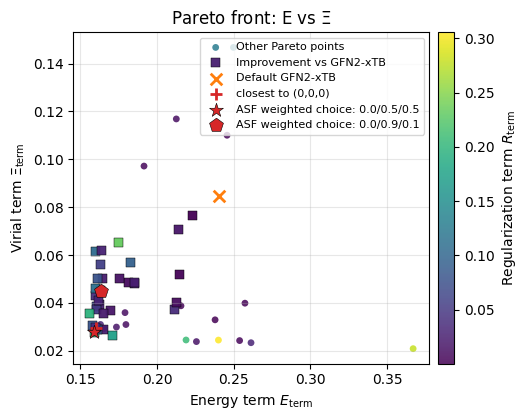

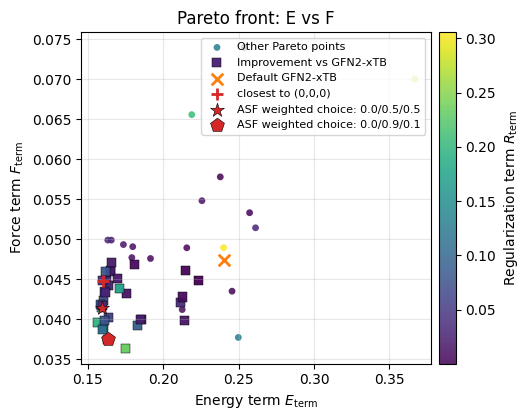

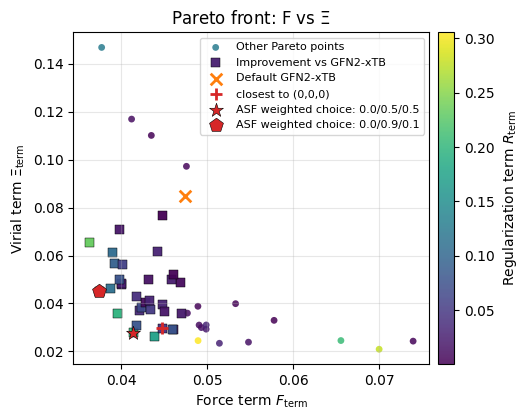

In [7]:
# plot 3 and 11 points in addition to knee (37)
asf_objectives_11 = F_pareto[11]

from matplotlib.colors import Normalize
from matplotlib.lines import Line2D

# ----------------------- Plot styling ----------------------- #

# Improvement marker:
# здесь я использую твой better_mask:
# E,F,Xi не хуже default, и хотя бы одна цель лучше.
improvement_mask = better_mask
other_mask = ~improvement_mask

# Color encodes regularization.
# Можно заменить "magma" на "viridis", "plasma", "cividis".
reg_cmap = "viridis"

reg_norm = Normalize(
    vmin=np.nanmin(Reg_term),
    vmax=np.nanmax(Reg_term),
)


def plot_pareto_with_reg_heatmap(
    x, y,
    x0, y0,
    knee_x, knee_y,
    asf_x, asf_y,
    asf_11_x, asf_11_y,
    xlabel, ylabel, title,
):
    fig, ax = plt.subplots(figsize=(5.4, 4.3))

    # Other Pareto points: circles
    sc = ax.scatter(
        x[other_mask],
        y[other_mask],
        c=Reg_term[other_mask],
        cmap=reg_cmap,
        norm=reg_norm,
        s=24,
        marker="o",
        alpha=0.85,
        edgecolors="none",
        label="Other Pareto points",
    )

    # Improved solutions: squares
    ax.scatter(
        x[improvement_mask],
        y[improvement_mask],
        c=Reg_term[improvement_mask],
        cmap=reg_cmap,
        norm=reg_norm,
        s=42,
        marker="s",
        alpha=0.95,
        edgecolors="black",
        linewidths=0.35,
        label=r"Improvement vs GFN2-xTB",
    )

    # Reference / selected points
    ax.scatter(
        [x0], [y0],
        s=70,
        marker="x",
        c="tab:orange",
        linewidths=2.0,
        label="Default GFN2-xTB",
        zorder=5,
    )

    ax.scatter(
        [knee_x], [knee_y],
        s=80,
        marker="+",
        c="tab:red",
        linewidths=2.0,
        label="closest to (0,0,0)",
        zorder=6,
    )

    ax.scatter(
        [asf_x], [asf_y],
        s=110,
        marker="*",
        c="tab:red",
        edgecolors="black",
        linewidths=0.4,
        label="ASF weighted choice: 0.0/0.5/0.5",
        zorder=7,
    )
    
    ax.scatter(
        [asf_11_x], [asf_11_y],
        s=110,
        marker="p",
        c="tab:red",
        edgecolors="black",
        linewidths=0.4,
        label="ASF weighted choice: 0.0/0.9/0.1",
        zorder=7,
    )

    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    ax.set_title(title)

    ax.grid(True, alpha=0.3)

    cbar = fig.colorbar(sc, ax=ax, pad=0.02)
    cbar.set_label(r"Regularization term $R_{\mathrm{term}}$")

    ax.legend(fontsize=8, frameon=True)
    fig.tight_layout()
    plt.show()


# ----------------------- E vs Xi ----------------------- #

plot_pareto_with_reg_heatmap(
    x=E_term,
    y=Xi_term,
    x0=E0,
    y0=Xi0,
    knee_x=knee_objectives[0],
    knee_y=knee_objectives[2],
    asf_x=asf_objectives[0],
    asf_y=asf_objectives[2],
    asf_11_x=asf_objectives_11[0],
    asf_11_y=asf_objectives_11[2],
    xlabel=r"Energy term $E_{\mathrm{term}}$",
    ylabel=r"Virial term $\Xi_{\mathrm{term}}$",
    title=r"Pareto front: E vs $\Xi$",
)


# ----------------------- E vs F ----------------------- #

plot_pareto_with_reg_heatmap(
    x=E_term,
    y=F_term,
    x0=E0,
    y0=F0,
    knee_x=knee_objectives[0],
    knee_y=knee_objectives[1],
    asf_x=asf_objectives[0],
    asf_y=asf_objectives[1],
    asf_11_x=asf_objectives_11[0],
    asf_11_y=asf_objectives_11[1],
    xlabel=r"Energy term $E_{\mathrm{term}}$",
    ylabel=r"Force term $F_{\mathrm{term}}$",
    title=r"Pareto front: E vs F",
)


# ----------------------- F vs Xi ----------------------- #

plot_pareto_with_reg_heatmap(
    x=F_term,
    y=Xi_term,
    x0=F0,
    y0=Xi0,
    knee_x=knee_objectives[1],
    knee_y=knee_objectives[2],
    asf_x=asf_objectives[1],
    asf_y=asf_objectives[2],
    asf_11_x=asf_objectives_11[1],
    asf_11_y=asf_objectives_11[2],
    xlabel=r"Force term $F_{\mathrm{term}}$",
    ylabel=r"Virial term $\Xi_{\mathrm{term}}$",
    title=r"Pareto front: F vs $\Xi$",
)

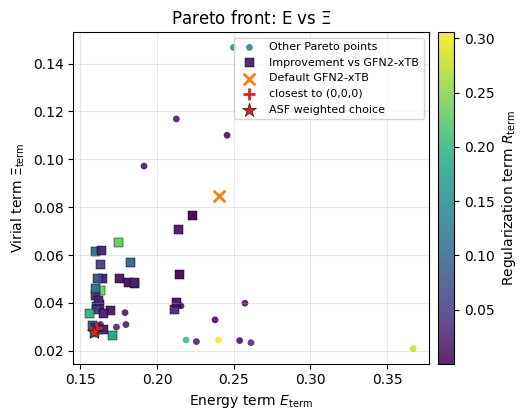

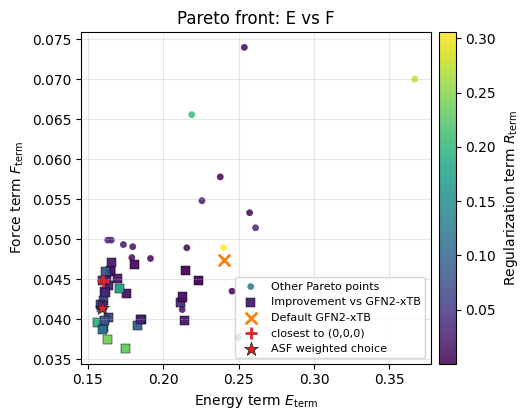

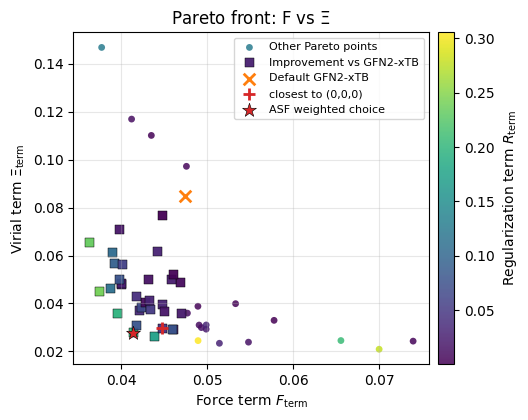

In [8]:
from matplotlib.colors import Normalize
from matplotlib.lines import Line2D

# ----------------------- Plot styling ----------------------- #

# Improvement marker:
# здесь я использую твой better_mask:
# E,F,Xi не хуже default, и хотя бы одна цель лучше.
improvement_mask = better_mask
other_mask = ~improvement_mask

# Color encodes regularization.
# Можно заменить "magma" на "viridis", "plasma", "cividis".
reg_cmap = "viridis"

reg_norm = Normalize(
    vmin=np.nanmin(Reg_term),
    vmax=np.nanmax(Reg_term),
)


def plot_pareto_with_reg_heatmap(
    x, y,
    x0, y0,
    knee_x, knee_y,
    asf_x, asf_y,
    xlabel, ylabel, title,
):
    fig, ax = plt.subplots(figsize=(5.4, 4.3))

    # Other Pareto points: circles
    sc = ax.scatter(
        x[other_mask],
        y[other_mask],
        c=Reg_term[other_mask],
        cmap=reg_cmap,
        norm=reg_norm,
        s=24,
        marker="o",
        alpha=0.85,
        edgecolors="none",
        label="Other Pareto points",
    )

    # Improved solutions: squares
    ax.scatter(
        x[improvement_mask],
        y[improvement_mask],
        c=Reg_term[improvement_mask],
        cmap=reg_cmap,
        norm=reg_norm,
        s=42,
        marker="s",
        alpha=0.95,
        edgecolors="black",
        linewidths=0.35,
        label=r"Improvement vs GFN2-xTB",
    )

    # Reference / selected points
    ax.scatter(
        [x0], [y0],
        s=70,
        marker="x",
        c="tab:orange",
        linewidths=2.0,
        label="Default GFN2-xTB",
        zorder=5,
    )

    ax.scatter(
        [knee_x], [knee_y],
        s=80,
        marker="+",
        c="tab:red",
        linewidths=2.0,
        label="closest to (0,0,0)",
        zorder=6,
    )

    ax.scatter(
        [asf_x], [asf_y],
        s=110,
        marker="*",
        c="tab:red",
        edgecolors="black",
        linewidths=0.4,
        label="ASF weighted choice",
        zorder=7,
    )

    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    ax.set_title(title)

    ax.grid(True, alpha=0.3)

    cbar = fig.colorbar(sc, ax=ax, pad=0.02)
    cbar.set_label(r"Regularization term $R_{\mathrm{term}}$")

    ax.legend(fontsize=8, frameon=True)
    fig.tight_layout()
    plt.show()


# ----------------------- E vs Xi ----------------------- #

plot_pareto_with_reg_heatmap(
    x=E_term,
    y=Xi_term,
    x0=E0,
    y0=Xi0,
    knee_x=knee_objectives[0],
    knee_y=knee_objectives[2],
    asf_x=asf_objectives[0],
    asf_y=asf_objectives[2],
    xlabel=r"Energy term $E_{\mathrm{term}}$",
    ylabel=r"Virial term $\Xi_{\mathrm{term}}$",
    title=r"Pareto front: E vs $\Xi$",
)


# ----------------------- E vs F ----------------------- #

plot_pareto_with_reg_heatmap(
    x=E_term,
    y=F_term,
    x0=E0,
    y0=F0,
    knee_x=knee_objectives[0],
    knee_y=knee_objectives[1],
    asf_x=asf_objectives[0],
    asf_y=asf_objectives[1],
    xlabel=r"Energy term $E_{\mathrm{term}}$",
    ylabel=r"Force term $F_{\mathrm{term}}$",
    title=r"Pareto front: E vs F",
)


# ----------------------- F vs Xi ----------------------- #

plot_pareto_with_reg_heatmap(
    x=F_term,
    y=Xi_term,
    x0=F0,
    y0=Xi0,
    knee_x=knee_objectives[1],
    knee_y=knee_objectives[2],
    asf_x=asf_objectives[1],
    asf_y=asf_objectives[2],
    xlabel=r"Force term $F_{\mathrm{term}}$",
    ylabel=r"Virial term $\Xi_{\mathrm{term}}$",
    title=r"Pareto front: F vs $\Xi$",
)